# AI61201: Visual Computing with AI/ML
### **Programming Assignment 5**: Semantic Segmentation Using U-Net

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch

## Task 1: Dataset Loading and Visualization (3 Marks)

-  Load the PASCAL VOC 2012 segmentation dataset using either the `torchvision.datasets.VOCSegmentation` class or the Kaggle dataset provided below.
[Download PASCAL VOC 2012 Segmentation Dataset – Kaggle](https://www.kaggle.com/datasets/sovitrath/voc-2012-segmentation-data) [1 Mark]

In [2]:
from torchvision.datasets import VOCSegmentation

data_dir = "./data"

# Load the datasets
# Set download=True for the first time
train_dataset = VOCSegmentation(root=data_dir, year="2012", image_set="train", download=False)
val_dataset = VOCSegmentation(root=data_dir, year="2012", image_set="val", download=False)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Training samples: 1464
Validation samples: 1449


- Visualize at least three sample images along with their corresponding ground-truth segmentation masks. Display the images and masks with appropriate labels. [1 Mark]

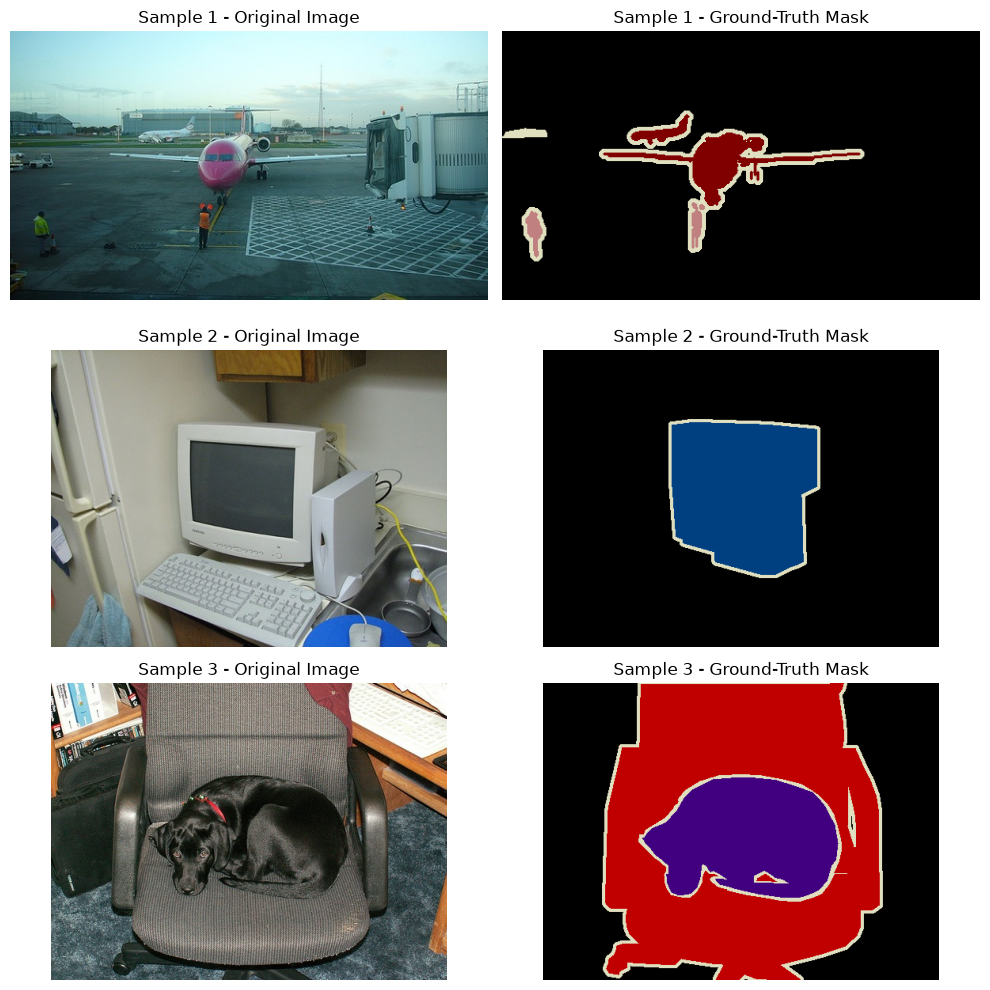

In [3]:
# Visualize three sample images and their ground-truth masks
num_samples = 3
fig, axes = plt.subplots(num_samples, 2, figsize=(10, 10))

for i in range(num_samples):
    image, mask = train_dataset[i]

    # Display original image
    axes[i, 0].imshow(image)
    axes[i, 0].set_title(f"Sample {i + 1} - Original Image")
    axes[i, 0].axis("off")

    # Display ground-truth segmentation mask
    axes[i, 1].imshow(mask.convert("RGB"))
    axes[i, 1].set_title(f"Sample {i + 1} - Ground-Truth Mask")
    axes[i, 1].axis("off")

plt.tight_layout()

## Task 2: Data Splitting and Preprocessing (4 Marks)

- Divide the available training dataset into training (80%) and validation (20%) subsets. Use the validation subset as the test set for final evaluation. A separate test split is not required. [1 Mark]

In [4]:
from torch.utils.data import random_split

# Define split sizes
total_samples = len(train_dataset)
train_size = int(0.8 * total_samples)
val_size = total_samples - train_size

# Set random seed for reproducibility
generator = torch.Generator().manual_seed(42)

# Split dataset into training and validation subsets
train_subset, val_subset = random_split(train_dataset, [train_size, val_size], generator=generator)

print("Total samples:", total_samples)
print("Training subset:", len(train_subset))
print("Validation/Test subset:", len(val_subset))

Total samples: 1464
Training subset: 1171
Validation/Test subset: 293


- Create PyTorch ‘DataLoader’ objects for the training, validation and test sets. The validation and test DataLoaders should use the same 20% subset. [1 Mark]

In [5]:
from torch.utils.data import DataLoader

# Custom collate function to retain raw PIL images and masks
def collate_fn(batch):
    images, masks = zip(*batch)
    return list(images), list(masks)

batch_size = 4

# Training DataLoader
train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 293
Validation batches: 74
Test batches: 74


- Resize all input images and their corresponding segmentation masks to a uniform spatial dimension (e.g., 224 × 224). Use nearest-neighbor interpolation for segmentation masks to preserve class labels. [1 Mark]

In [6]:
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

image_size = (224, 224)

def collate_fn(batch):
    images, masks = zip(*batch)

    # Resize images using bilinear interpolation
    images = [TF.resize(img, image_size, interpolation=InterpolationMode.BILINEAR) for img in images]

    # Resize masks using nearest-neighbor interpolation
    masks = [TF.resize(mask, image_size, interpolation=InterpolationMode.NEAREST) for mask in masks]

    return list(images), list(masks)

# Update the existing DataLoaders
train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)

# Verify
images, masks = next(iter(train_loader))

print("Image size:", images[0].size)
print("Mask size:", masks[0].size)

Image size: (224, 224)
Mask size: (224, 224)


- Apply data augmentation to the training set using random flips, random rotation and color jitter. Ensure that spatial transformations are applied consistently to both images and masks. Color jitter must be applied only to the input images. No augmentation should be applied to the validation/test data. [1 Mark]

In [7]:
import random
from torchvision.transforms import ColorJitter

# Define color jitter for input images only
color_jitter = ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05)

# Training collate function with augmentation
def train_collate_fn(batch):
    images, masks = zip(*batch)

    augmented_images = []
    augmented_masks = []

    for image, mask in zip(images, masks):

        # Resize images and masks to 224x224
        image = TF.resize(image, (224, 224), interpolation=InterpolationMode.BILINEAR)
        mask = TF.resize(mask, (224, 224), interpolation=InterpolationMode.NEAREST)

        # Apply random horizontal flip
        if random.random() < 0.5:
            image = TF.hflip(image)
            mask = TF.hflip(mask)

        # Apply random rotation using the same angle
        angle = random.uniform(-15, 15)
        image = TF.rotate(image, angle, interpolation=InterpolationMode.BILINEAR, fill=0)
        mask = TF.rotate(mask, angle, interpolation=InterpolationMode.NEAREST, fill=255)

        # Apply color jitter only to the image
        image = color_jitter(image)

        augmented_images.append(image)
        augmented_masks.append(mask)

    return augmented_images, augmented_masks

def eval_collate_fn(batch):
    images, masks = zip(*batch)

    # Resize images using bilinear interpolation
    images = [TF.resize(image, (224, 224), interpolation=InterpolationMode.BILINEAR) for image in images]

    # Resize masks using nearest-neighbor interpolation
    masks = [TF.resize(mask, (224, 224), interpolation=InterpolationMode.NEAREST) for mask in masks]

    return list(images), list(masks)

# Training DataLoader with augmentation
train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True, collate_fn=train_collate_fn)

# Validation and Test DataLoaders without augmentation
val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False, collate_fn=eval_collate_fn)
test_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False, collate_fn=eval_collate_fn)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 293
Validation batches: 74
Test batches: 74


Sample 1 mask labels: [  0  12  15 255]
Sample 2 mask labels: [  0   4 255]
Sample 3 mask labels: [  0  13 255]


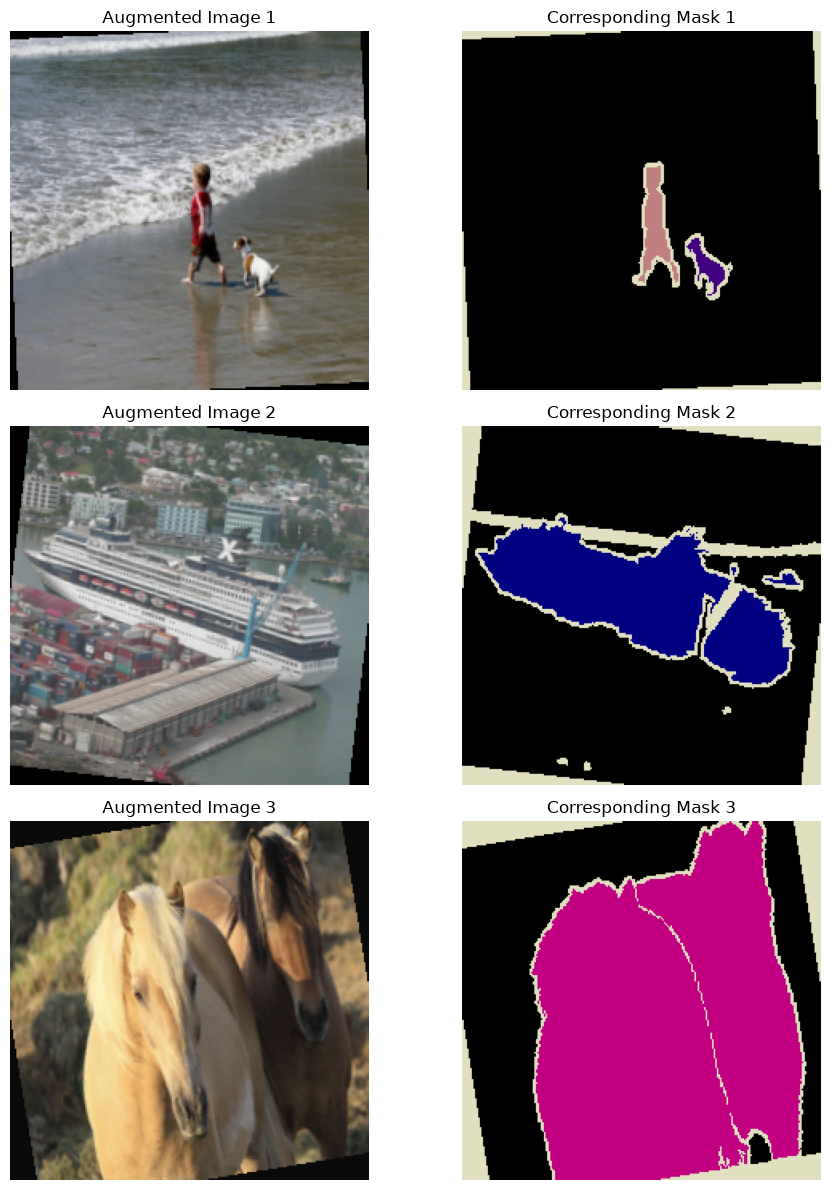

In [8]:
# Visualize augmented training samples
images, masks = next(iter(train_loader))
fig, axes = plt.subplots(3, 2, figsize=(10, 12))

for i in range(3):
    axes[i, 0].imshow(images[i])
    axes[i, 0].set_title(f"Augmented Image {i + 1}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(masks[i].convert("RGB"))
    axes[i, 1].set_title(f"Corresponding Mask {i + 1}")
    axes[i, 1].axis("off")

plt.tight_layout()

# Check unique labels after augmentation
for i in range(3):
    print(f"Sample {i + 1} mask labels:", np.unique(np.array(masks[i])))

## Task 3: U-Net Architecture Design (5 Marks)

- Design a small U-Net architecture from scratch. The implementation should explicitly include the encoder (downsampling path), bottleneck, decoder (upsampling path) and skip connections that concatenate the corresponding encoder feature maps with decoder feature maps. Keep the U-Net architecture relatively lightweight, considering the size of the available training dataset. Avoid unnecessarily complex architectures that may lead to overfitting. [4 Marks]

In [45]:
import torch
import torch.nn as nn

# Double convolution block
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


# Encoder block with max pooling
class EncoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = ConvBlock(in_channels, out_channels)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        features = self.conv(x)
        pooled = self.pool(features)

        return features, pooled


# Decoder block with transposed convolution and skip connection
class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()

        self.up = nn.ConvTranspose2d(
            in_channels, out_channels, kernel_size=2, stride=2
        )

        self.conv = ConvBlock(out_channels + skip_channels, out_channels)

    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([x, skip], dim=1)

        return self.conv(x)


# U-Net architecture
class UNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=21):
        super().__init__()

        # Encoder
        self.enc1 = EncoderBlock(in_channels, 32)
        self.enc2 = EncoderBlock(32, 64)
        self.enc3 = EncoderBlock(64, 128)

        # Bottleneck
        self.bottleneck = ConvBlock(128, 256)

        # Decoder
        self.dec3 = DecoderBlock(256, 128, 128)
        self.dec2 = DecoderBlock(128, 64, 64)
        self.dec1 = DecoderBlock(64, 32, 32)

        # Output layer
        self.final = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        # Encoder
        skip1, x = self.enc1(x)
        skip2, x = self.enc2(x)
        skip3, x = self.enc3(x)

        # Bottleneck
        x = self.bottleneck(x)

        # Decoder with skip connections
        x = self.dec3(x, skip3)
        x = self.dec2(x, skip2)
        x = self.dec1(x, skip1)

        return self.final(x)

In [46]:
# Select computation device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Initialize U-Net
model = UNet(num_classes=21).to(device)

# Count trainable parameters
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Device:", device)
print("Trainable parameters:", f"{total_params:,}")

Device: cuda
Trainable parameters: 1,926,261


In [47]:
# Create a dummy input batch
dummy_input = torch.randn(4, 3, 224, 224).to(device)

# Perform forward pass
model.eval()

with torch.no_grad():
    output = model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([4, 3, 224, 224])
Output shape: torch.Size([4, 21, 224, 224])


- Display the model summary using the ‘summary()’ function from the ‘torchinfo’ library and report the total number of trainable parameters in the model. [1 Mark]

In [48]:
from torchinfo import summary

# Display U-Net model summary
summary(
    model,
    input_size=(4, 3, 224, 224),
    device=device,
    col_names=["input_size", "output_size", "num_params"],
    depth=3
)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
UNet                                     [4, 3, 224, 224]          [4, 21, 224, 224]         --
├─EncoderBlock: 1-1                      [4, 3, 224, 224]          [4, 32, 224, 224]         --
│    └─ConvBlock: 2-1                    [4, 3, 224, 224]          [4, 32, 224, 224]         --
│    │    └─Sequential: 3-1              [4, 3, 224, 224]          [4, 32, 224, 224]         10,144
│    └─MaxPool2d: 2-2                    [4, 32, 224, 224]         [4, 32, 112, 112]         --
├─EncoderBlock: 1-2                      [4, 32, 112, 112]         [4, 64, 112, 112]         --
│    └─ConvBlock: 2-3                    [4, 32, 112, 112]         [4, 64, 112, 112]         --
│    │    └─Sequential: 3-2              [4, 32, 112, 112]         [4, 64, 112, 112]         55,424
│    └─MaxPool2d: 2-4                    [4, 64, 112, 112]         [4, 64, 56, 56]           --
├─EncoderBlock: 1-3        

In [49]:
# Count trainable parameters
total_params = sum(
    param.numel()
    for param in model.parameters()
    if param.requires_grad
)

print(f"Total trainable parameters: {total_params:,}")

Total trainable parameters: 1,926,261


## Task 4: Model Training (5 Marks)

- Train the U-Net model using the Adam optimizer and Cross-Entropy Loss. [2 Marks]

In [50]:
import torch.optim as optim
from torchvision.transforms import functional as TF

criterion = nn.CrossEntropyLoss(ignore_index=255)
print("Loss function:", criterion)

Loss function: CrossEntropyLoss()


- Select and specify a suitable learning rate, batch size and number of training epochs. [1 Mark]

In [51]:
learning_rate = 0.001
batch_size = 8
num_epochs = 10

optimizer = optim.Adam(model.parameters(), lr=learning_rate)
print("Optimizer:", optimizer)

Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


- Configure the final layer of the U-Net to predict the 21 semantic classes of the
PASCAL VOC dataset, including the background class.

In [52]:
# The defined UNet architecture already supports prediction
# of 21 semnatic classes of the PASCAL VOC dataset

dummy_input = torch.randn(1, 3, 224, 224).to(device)
output = model(dummy_input)
print("Output shape:", output.shape)

predicted_mask = torch.argmax(output, dim=1)
print("Predicted mask shape:", predicted_mask.shape)

Output shape: torch.Size([1, 21, 224, 224])
Predicted mask shape: torch.Size([1, 224, 224])


- Configure the loss function to ignore the void/border label index ‘255’ present in
the segmentation masks using ‘ignore_index=255’ in Cross-Entropy Loss. [1 Mark]

In [ ]:
criterion = nn.CrossEntropyLoss(ignore_index=255)
print("Loss function:", criterion)

Loss function: CrossEntropyLoss()


- Implement the training loop and validation process. Record the average training and validation losses for each epoch. [1 Mark]

In [59]:
train_losses = []
val_losses = []

# ImageNet RGB channel-wise mean and standard deviation used for normalization
mean = [0.485, 0.456, 0.406]  # Red, Green, Blue
std = [0.229, 0.224, 0.225]   # Red, Green, Blue

for epoch in range(num_epochs):
    # Training phase
    model.train()
    running_train_loss = 0.0

    for images, masks in train_loader:
        images = torch.stack([
            TF.normalize(TF.to_tensor(image), mean, std)
            for image in images
        ]).to(device)

        masks = torch.stack([
            torch.from_numpy(np.array(mask, dtype=np.int64))
            for mask in masks
        ]).to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, masks)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    avg_train_loss = running_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # Validation phase
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for images, masks in val_loader:
            images = torch.stack([
                TF.normalize(TF.to_tensor(image), mean, std)
                for image in images
            ]).to(device)

            masks = torch.stack([
                torch.from_numpy(np.array(mask, dtype=np.int64))
                for mask in masks
            ]).to(device)

            outputs = model(images)
            loss = criterion(outputs, masks)

            running_val_loss += loss.item()

    avg_val_loss = running_val_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Validation Loss: {avg_val_loss:.4f}"
    )

Epoch [1/10] | Train Loss: 1.2727 | Validation Loss: 1.3191
Epoch [2/10] | Train Loss: 1.2733 | Validation Loss: 1.3127
Epoch [3/10] | Train Loss: 1.2647 | Validation Loss: 1.3033
Epoch [4/10] | Train Loss: 1.2598 | Validation Loss: 1.2975
Epoch [5/10] | Train Loss: 1.2557 | Validation Loss: 1.3263
Epoch [6/10] | Train Loss: 1.2559 | Validation Loss: 1.3027
Epoch [7/10] | Train Loss: 1.2595 | Validation Loss: 1.3157
Epoch [8/10] | Train Loss: 1.2535 | Validation Loss: 1.3027
Epoch [9/10] | Train Loss: 1.2506 | Validation Loss: 1.3015
Epoch [10/10] | Train Loss: 1.2478 | Validation Loss: 1.3068


## Task 5: Training Diagnostics (2 Marks)
- Plot and display the training loss and validation loss against the number of epochs on a single graph. Ensure that the graph has properly labeled axes and a legend. [1 Mark]

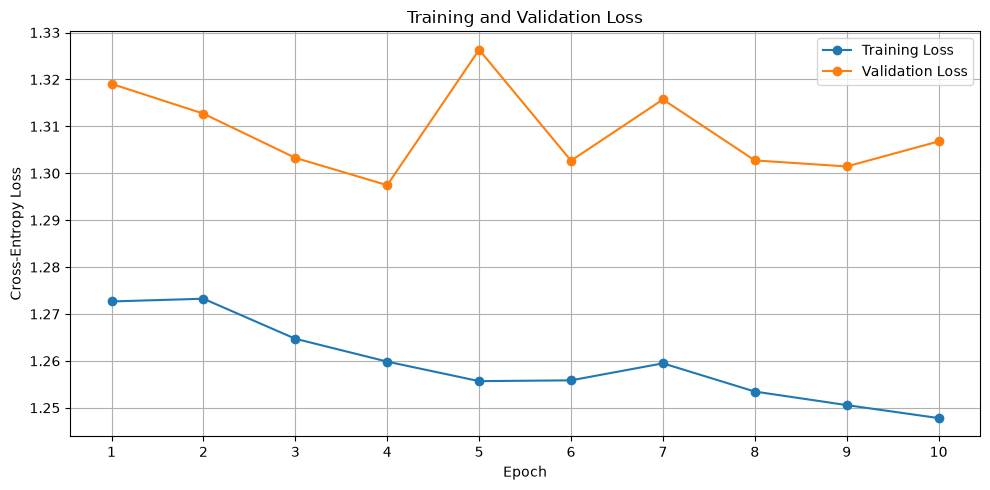

In [60]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(train_losses) + 1), train_losses, marker='o', label='Training Loss')
plt.plot(range(1, len(val_losses) + 1), val_losses, marker='o', label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Cross-Entropy Loss')
plt.title('Training and Validation Loss')
plt.xticks(range(1, len(train_losses) + 1))
plt.legend()
plt.grid(True)
plt.tight_layout()

## Task 6: Evaluation on Test Set

- Report the following on the test set: [2 Marks]
    - Pixel accuracy
    - Per class intersection over union
    - Mean IoU over all classes

In [61]:
num_classes = 21
class_names = [
    "Background", "Aeroplane", "Bicycle", "Bird", "Boat",
    "Bottle", "Bus", "Car", "Cat", "Chair", "Cow",
    "Diningtable", "Dog", "Horse", "Motorbike", "Person",
    "Pottedplant", "Sheep", "Sofa", "Train", "Tvmonitor"
]

model.eval()
confusion_matrix = torch.zeros(num_classes, num_classes, dtype=torch.int64, device=device)

with torch.no_grad():
    for images, masks in test_loader:
        images = torch.stack([
            TF.normalize(TF.to_tensor(image), mean, std)
            for image in images
        ]).to(device)

        masks = torch.stack([
            torch.from_numpy(np.array(mask, dtype=np.int64))
            for mask in masks
        ]).to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        # Exclude void pixels (label 255)
        valid_pixels = masks != 255

        targets = masks[valid_pixels]
        preds = predictions[valid_pixels]

        # Update confusion matrix
        indices = targets * num_classes + preds

        confusion_matrix += torch.bincount(
            indices,
            minlength=num_classes * num_classes
        ).reshape(num_classes, num_classes)

# Convert confusion matrix to NumPy
confusion_matrix = confusion_matrix.cpu().numpy()

# Calculate pixel accuracy
pixel_accuracy = np.diag(confusion_matrix).sum() / confusion_matrix.sum()

# Calculate per-class IoU
intersection = np.diag(confusion_matrix)
union = (
    confusion_matrix.sum(axis=1)
    + confusion_matrix.sum(axis=0)
    - intersection
)

per_class_iou = np.divide(
    intersection,
    union,
    out=np.full(num_classes, np.nan, dtype=float),
    where=union != 0
)

# Calculate mean IoU (excluding classes absent from the test set)
mean_iou = np.nanmean(per_class_iou)

print(f"Pixel Accuracy: {pixel_accuracy:.4f}")
print(f"Mean IoU: {mean_iou:.4f}")

print("\nPer-Class IoU:")
for name, iou in zip(class_names, per_class_iou):
    print(f"{name:15s}: {iou:.4f}" if not np.isnan(iou)
          else f"{name:15s}: N/A")

Pixel Accuracy: 0.7210
Mean IoU: 0.0344

Per-Class IoU:
Background     : 0.7210
Aeroplane      : 0.0000
Bicycle        : 0.0000
Bird           : 0.0000
Boat           : 0.0000
Bottle         : 0.0000
Bus            : 0.0000
Car            : 0.0000
Cat            : 0.0000
Chair          : 0.0000
Cow            : 0.0000
Diningtable    : 0.0000
Dog            : 0.0000
Horse          : 0.0000
Motorbike      : 0.0000
Person         : 0.0012
Pottedplant    : 0.0000
Sheep          : 0.0000
Sofa           : 0.0000
Train          : 0.0000
Tvmonitor      : 0.0000


### Analysis of Results

The U-Net achieved a pixel accuracy of **72.10%** and a mean IoU of **3.44%**. The model performs well only on the background class (IoU = 0.7210), while almost all foreground classes have zero IoU. The Person class has a negligible IoU of 0.0012.

This indicates a strong bias toward background predictions due to severe class imbalance. 

### Possible Solutions

1. Increase the contribution of foreground classes through appropriate class weights and Dice Loss.
2. Use stronger data augmentation, such as random scaling and cropping.
3. Train the model for more epochs with a learning-rate scheduler.
4. Use transfer learning with a pretrained encoder such as ResNet-18 to improve feature extraction.

**Conclusion:** Despite achieving reasonable pixel accuracy, the model exhibits poor foreground segmentation. Addressing class imbalance and improving feature extraction may help improve the overall segmentation performance. **Hence the model was fine-tuned with weighted cross-entropy loss.**

In [62]:
num_classes = 21
class_pixel_counts = np.zeros(num_classes, dtype=np.int64)

for _, mask in train_subset:
    mask = TF.resize(mask, (224, 224), interpolation=InterpolationMode.NEAREST)
    mask = np.array(mask, dtype=np.int64)
    valid_pixels = mask != 255
    class_pixel_counts += np.bincount(mask[valid_pixels], minlength=num_classes)[:num_classes]

class_frequencies = class_pixel_counts / class_pixel_counts.sum()

print("Class frequencies:")
for name, frequency in zip(class_names, class_frequencies):
    print(f"{name:15s}: {frequency:.4%}")

present_classes = class_frequencies > 0
median_frequency = np.median(class_frequencies[present_classes])

class_weights = np.zeros(21, dtype=np.float32)
class_weights[present_classes] = np.sqrt(
    median_frequency / class_frequencies[present_classes]
)

class_weights = np.clip(class_weights, 0.25, 5.0)
class_weights = class_weights / class_weights[present_classes].mean()

class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

weighted_criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=255
)

# init class weights
present_classes = class_frequencies > 0
median_frequency = np.median(class_frequencies[present_classes])

class_weights = np.zeros(num_classes, dtype=np.float32)
class_weights[present_classes] = np.sqrt(median_frequency / class_frequencies[present_classes])

class_weights = np.clip(class_weights, 0.25, 5.0)
class_weights = class_weights / class_weights[present_classes].mean()
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

print("Class weights:", class_weights.cpu().numpy())

Class frequencies:
Background     : 73.7625%
Aeroplane      : 0.7336%
Bicycle        : 0.3140%
Bird           : 0.8106%
Boat           : 0.6237%
Bottle         : 0.5009%
Bus            : 1.7523%
Car            : 1.4160%
Cat            : 2.3382%
Chair          : 1.1029%
Cow            : 0.9191%
Diningtable    : 1.2274%
Dog            : 1.8439%
Horse          : 0.9098%
Motorbike      : 1.2575%
Person         : 4.9705%
Pottedplant    : 0.5375%
Sheep          : 0.9054%
Sofa           : 1.5281%
Train          : 1.6215%
Tvmonitor      : 0.9246%
Class weights: [0.2462341  1.20764    1.8458991  1.1488988  1.3097272  1.4615577
 0.7814169  0.86926335 0.6764605  0.9849364  1.0789685  0.9336451
 0.76175976 1.0844321  0.9224327  0.46396098 1.4108922  1.0870887
 0.8367665  0.81230706 1.0757155 ]


In [63]:
import torch.nn.functional as F

weighted_criterion = nn.CrossEntropyLoss(weight=class_weights, ignore_index=255)

def segmentation_loss(outputs, masks):
    ce_loss = weighted_criterion(outputs, masks)

    probabilities = F.softmax(outputs, dim=1)
    valid_pixels = (masks != 255).unsqueeze(1)

    safe_masks = masks.clamp(0, 20)
    targets = F.one_hot(safe_masks, num_classes=21).permute(0, 3, 1, 2).float()

    probabilities = probabilities * valid_pixels
    targets = targets * valid_pixels

    intersection = (probabilities * targets).sum(dim=(0, 2, 3))
    denominator = probabilities.sum(dim=(0, 2, 3)) + targets.sum(dim=(0, 2, 3))

    dice_score = (2 * intersection[1:] + 1) / (denominator[1:] + 1)
    dice_loss = 1 - dice_score.mean()

    return 0.5 * ce_loss + 0.5 * dice_loss

In [64]:
import copy

optimizer = optim.Adam(model.parameters(), lr=0.0001)

epochs = 8
best_val_loss = float("inf")
best_model_state = copy.deepcopy(model.state_dict())

In [65]:
# Fine-tune the model
for epoch in range(epochs):

    model.train()
    train_loss = 0.0

    for images, masks in train_loader:
        images = torch.stack([TF.normalize(TF.to_tensor(image), mean, std) for image in images]).to(device)
        masks = torch.stack([torch.from_numpy(np.array(mask, dtype=np.int64)) for mask in masks]).to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = segmentation_loss(outputs, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)

    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for images, masks in val_loader:
            images = torch.stack([TF.normalize(TF.to_tensor(image), mean, std) for image in images]).to(device)
            masks = torch.stack([torch.from_numpy(np.array(mask, dtype=np.int64)) for mask in masks]).to(device)

            outputs = model(images)
            loss = segmentation_loss(outputs, masks)
            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_model_state = copy.deepcopy(model.state_dict())

    print(f"Epoch [{epoch + 1}/{epochs}] | Train Loss: {avg_train_loss:.4f} | Validation Loss: {avg_val_loss:.4f}")

Epoch [1/8] | Train Loss: 1.5528 | Validation Loss: 1.5660
Epoch [2/8] | Train Loss: 1.5431 | Validation Loss: 1.5645
Epoch [3/8] | Train Loss: 1.5380 | Validation Loss: 1.5619
Epoch [4/8] | Train Loss: 1.5304 | Validation Loss: 1.5628
Epoch [5/8] | Train Loss: 1.5337 | Validation Loss: 1.5584
Epoch [6/8] | Train Loss: 1.5323 | Validation Loss: 1.5586
Epoch [7/8] | Train Loss: 1.5310 | Validation Loss: 1.5569
Epoch [8/8] | Train Loss: 1.5274 | Validation Loss: 1.5558


In [66]:
model.load_state_dict(best_model_state)
print("Best fine-tuned model loaded successfully.")

# Evaluate the fine-tuned model
model.eval()
confusion_matrix = torch.zeros(num_classes, num_classes, dtype=torch.int64, device=device)

with torch.no_grad():
    for images, masks in test_loader:
        images = torch.stack([
            TF.normalize(TF.to_tensor(image), mean, std)
            for image in images
        ]).to(device)

        masks = torch.stack([
            torch.from_numpy(np.array(mask, dtype=np.int64))
            for mask in masks
        ]).to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        # Exclude void pixels (label 255)
        valid_pixels = masks != 255

        targets = masks[valid_pixels]
        preds = predictions[valid_pixels]

        # Update confusion matrix
        indices = targets * num_classes + preds

        confusion_matrix += torch.bincount(
            indices,
            minlength=num_classes * num_classes
        ).reshape(num_classes, num_classes)

# Convert confusion matrix to NumPy
confusion_matrix = confusion_matrix.cpu().numpy()

# Calculate pixel accuracy
pixel_accuracy = np.diag(confusion_matrix).sum() / confusion_matrix.sum()

# Calculate per-class IoU
intersection = np.diag(confusion_matrix)
union = (
    confusion_matrix.sum(axis=1)
    + confusion_matrix.sum(axis=0)
    - intersection
)

per_class_iou = np.divide(
    intersection,
    union,
    out=np.full(num_classes, np.nan, dtype=float),
    where=union != 0
)

# Calculate mean IoU (excluding classes absent from the test set)
mean_iou = np.nanmean(per_class_iou)

print(f"Pixel Accuracy: {pixel_accuracy:.4f}")
print(f"Mean IoU: {mean_iou:.4f}")

print("\nPer-Class IoU:")
for name, iou in zip(class_names, per_class_iou):
    print(f"{name:15s}: {iou:.4f}" if not np.isnan(iou)
          else f"{name:15s}: N/A")

Best fine-tuned model loaded successfully.
Pixel Accuracy: 0.7180
Mean IoU: 0.0372

Per-Class IoU:
Background     : 0.7221
Aeroplane      : 0.0000
Bicycle        : 0.0000
Bird           : 0.0000
Boat           : 0.0000
Bottle         : 0.0000
Bus            : 0.0000
Car            : 0.0000
Cat            : 0.0000
Chair          : 0.0000
Cow            : 0.0000
Diningtable    : 0.0000
Dog            : 0.0000
Horse          : 0.0000
Motorbike      : 0.0128
Person         : 0.0453
Pottedplant    : 0.0000
Sheep          : 0.0000
Sofa           : 0.0000
Train          : 0.0000
Tvmonitor      : 0.0000


- Show four randomly picked samples from the test set, their ground truth segmentation masks and segmentation masks predicted by the trained U-Net model. [1 Mark]

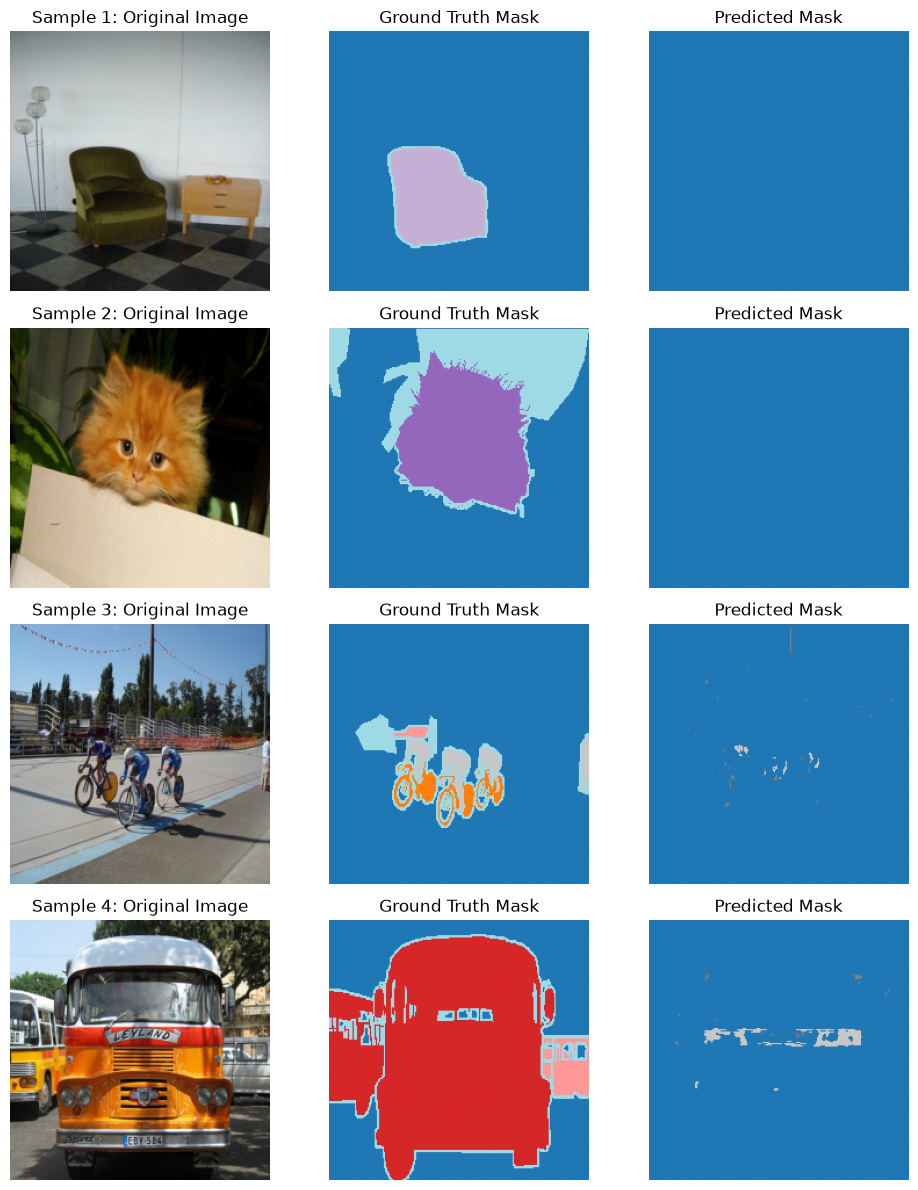

In [68]:
# Randomly select four samples from the test dataset
random.seed(42)
sample_indices = random.sample(range(len(test_loader.dataset)), 4)

model.eval()
fig, axes = plt.subplots(4, 3, figsize=(10, 12))

with torch.no_grad():
    for i, idx in enumerate(sample_indices):
        image, mask = test_loader.dataset[idx]

        # Resize image and mask to the model input size
        image = TF.resize(
            image, (224, 224),
            interpolation=InterpolationMode.BILINEAR
        )
        mask = TF.resize(
            mask, (224, 224),
            interpolation=InterpolationMode.NEAREST
        )

        # Preprocess image
        input_image = TF.normalize(TF.to_tensor(image), mean, std)
        input_image = input_image.unsqueeze(0).to(device)

        # Generate predicted segmentation mask
        output = model(input_image)
        prediction = torch.argmax(output, dim=1).squeeze(0).cpu().numpy()

        ground_truth = np.array(mask)

        # Display original image
        axes[i, 0].imshow(image)
        axes[i, 0].set_title(f"Sample {i + 1}: Original Image")

        # Display ground truth mask
        axes[i, 1].imshow(ground_truth, cmap="tab20", vmin=0, vmax=20)
        axes[i, 1].set_title("Ground Truth Mask")

        # Display predicted mask
        axes[i, 2].imshow(prediction, cmap="tab20", vmin=0, vmax=20)
        axes[i, 2].set_title("Predicted Mask")

        for ax in axes[i]:
            ax.axis("off")

plt.tight_layout()

---
End of the assignment